# Recorded CPU wall-clock runtimes for BSS experiments

We summarize the **recorded initialization-and-fitting wall-clock times** from four existing Monte Carlo experiments: **antisparse**, **sparse**, **nonnegative sparse (NNSparse)**, and **simplex**. All use 5 sources and 10 mixtures. No benchmark or training is rerun in this notebook; only the four saved local result files are read and aggregated.

**Interpretation and sample budgets.**
- PEM, the online CorInfoMax implementations, BSM, and InfoMax ICA receive **100,000 input samples**. The batch comparator (`LDMIBSS`, displayed below as **LDMI** and in the paper as **CorInfoMax (Batch)**) receives **10,000 samples** and runs **5,000 batch iterations**. InfoMax ICA also uses batch optimization. Wall-clock times are not normalized by sample count.
- Methods use their experiment-specific hyperparameters, inference horizons, and stopping criteria. These are **configuration-specific CPU timings**, not a controlled comparison of algorithmic speed or complexity.
- Antisparse results pool **30 seeds × 11 correlation settings** (330 runs per method) at 30 dB input SNR. Each other domain pools **30 seeds × 6 input SNR settings** (180 runs per method, 5–30 dB). These are repeated conditions for 30 seeds, not 330 or 180 independent seeds.
- We report the median and **mean ± sample standard deviation** across the recorded runs; the standard deviation uses `ddof=1` and is not a confidence interval. Medians do not remove initialization, diagnostics, or first-use Numba compilation from the recorded intervals.
- The timer covers initialization and fitting, including internal diagnostics and first-use compilation when triggered; InfoMax ICA also includes MNE setup and source extraction. Data generation and external post-fit scoring are outside the timer. The stored records do **not** identify CPU model, thread configuration, or an identical host across runs.
- BSM and InfoMax ICA occur only in the antisparse experiment; online CorInfoMax has no simplex run. `CorInfoMax` below denotes **CorInfoMax (Online)**. Missing combinations remain unreported.


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ONLINE_SAMPLES = 100_000
BATCH_SAMPLES = 10_000
RESULTS = "../Results/"
FILES = {
    "Antisparse": "predictive_bss_correlated_antisparse_10by5_results.pkl",
    "Sparse":     "predictive_bss_noisy_sparse_10by5_results.pkl",
    "NNSparse":   "predictive_bss_noisy_nnsparse_10by5_results.pkl",
    "Simplex":    "predictive_bss_noisy_simplex_10by5_results.pkl",
}
# display names (note: some pkls store "CorInfoMax", others "CorInfoMaxBSS" -> normalise both)
NAME = {"PredictiveDecorrBSS": "PEM (ours)", "CorInfoMaxBSS": "CorInfoMax", "CorInfoMax": "CorInfoMax",
        "LDMIBSS": "LDMI", "BSMBSS": "BSM", "ICA_InfoMax": "InfoMax ICA"}
COLOR = {"PEM (ours)": "#0072B2", "CorInfoMax": "#D55E00", "LDMI": "#009E73",
         "BSM": "#CC79A7", "InfoMax ICA": "#999999"}

data, SECONDARY = {}, {}
for exp, f in FILES.items():
    df = pd.read_pickle(RESULTS + f).copy()
    df["Algorithm"] = df["Model"].map(NAME).fillna(df["Model"])
    df["fit_input_samples"] = np.where(df["Model"].eq("LDMIBSS"), BATCH_SAMPLES, ONLINE_SAMPLES)
    assert np.isfinite(df["execution_time"]).all() and (df["execution_time"] > 0).all()
    SECONDARY[exp] = "rho" if "rho" in df.columns else "SNRinp"   # swept dimension
    data[exp] = df
    print(f"{exp:11s}: {df.shape[0]:4d} runs | sweep={SECONDARY[exp]:6s} | algos: {sorted(df['Algorithm'].unique())}")

Antisparse : 1650 runs | sweep=rho    | algos: ['BSM', 'CorInfoMax', 'InfoMax ICA', 'LDMI', 'PEM (ours)']
Sparse     :  540 runs | sweep=SNRinp | algos: ['CorInfoMax', 'LDMI', 'PEM (ours)']
NNSparse   :  540 runs | sweep=SNRinp | algos: ['CorInfoMax', 'LDMI', 'PEM (ours)']
Simplex    :  360 runs | sweep=SNRinp | algos: ['LDMI', 'PEM (ours)']


## 1. Per-algorithm recorded wall-clock time

Times pool the conditions described above. The input sample budget comes from the matching simulation driver, not from a new benchmark.


In [2]:
def summarize(df):
    g = df.groupby("Algorithm")["execution_time"]
    assert (df.groupby("Algorithm")["fit_input_samples"].nunique() == 1).all()
    t = pd.DataFrame({"runs": g.size(),
                      "fit input samples": df.groupby("Algorithm")["fit_input_samples"].first(),
                      "median (s)": g.median(), "mean (s)": g.mean(),
                      "std (s)": g.std(ddof=1), "min (s)": g.min(), "max (s)": g.max()})
    return t.sort_values("median (s)").round(2)

summaries = {exp: summarize(df) for exp, df in data.items()}
for exp, t in summaries.items():
    print(f"{exp.upper()}  (5 sources, 10 mixtures; method-specific sample budgets)")
    print(t.to_string()); print()


ANTISPARSE  (5 sources, 10 mixtures; method-specific sample budgets)
             runs  fit input samples  median (s)  mean (s)  std (s)  min (s)  max (s)
Algorithm                                                                            
BSM           330             100000        3.42      3.51     0.62     3.37    13.05
CorInfoMax    330             100000        5.50      5.58     0.42     5.37     9.40
InfoMax ICA   330             100000        6.15      6.21     0.30     5.62     8.91
LDMI          330              10000       10.06     10.26     0.88    10.01    19.44
PEM (ours)    330             100000       14.13     14.48     1.41    13.33    31.06

SPARSE  (5 sources, 10 mixtures; method-specific sample budgets)
            runs  fit input samples  median (s)  mean (s)  std (s)  min (s)  max (s)
Algorithm                                                                           
PEM (ours)   180             100000       14.06     14.60     2.41    11.96    35.40
LDMI    

## 2. Recorded distributions across all four domains

Bars show medians; black markers and whiskers show means ± sample standard deviations. These summarize the saved configurations and condition sweeps, without isolating causes of runtime differences.


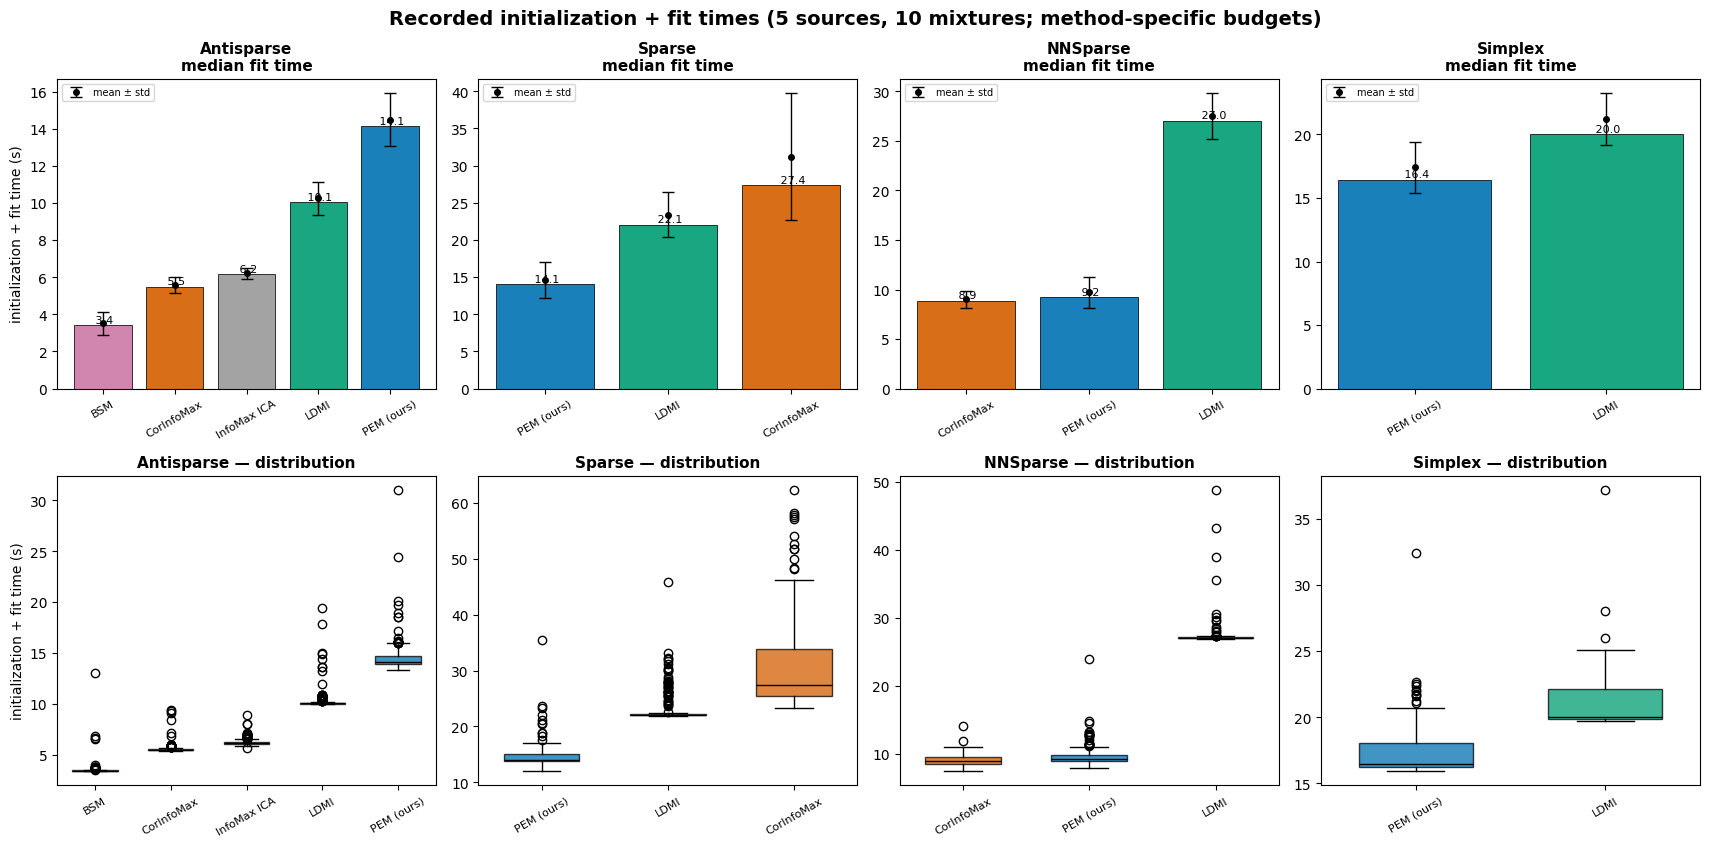

In [3]:
nexp = len(data)
fig, axes = plt.subplots(2, nexp, figsize=(4.3 * nexp, 8.6))
for col, (exp, df) in enumerate(data.items()):
    order = summaries[exp].index.tolist()                     # fastest -> slowest
    cols = [COLOR[a] for a in order]
    # (top) bar of median with mean/std whiskers
    ax = axes[0, col]
    med  = [summaries[exp].loc[a, "median (s)"] for a in order]
    mean = [df[df.Algorithm == a]["execution_time"].mean() for a in order]
    std  = [df[df.Algorithm == a]["execution_time"].std()  for a in order]
    ax.bar(order, med, color=cols, alpha=0.9, edgecolor="black", linewidth=0.6)
    ax.errorbar(order, mean, yerr=std, fmt="o", color="black", ms=4, lw=1, capsize=4,
                label="mean ± std")
    for i in range(len(order)):
        ax.text(i, med[i], f" {med[i]:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"{exp}\nmedian fit time", fontweight="bold", fontsize=11)
    if col == 0: ax.set_ylabel("initialization + fit time (s)")
    ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=30, labelsize=8)
    # (bottom) boxplot of the full distribution
    axb = axes[1, col]
    box = axb.boxplot([df[df.Algorithm == a]["execution_time"] for a in order],
                      patch_artist=True, showfliers=True, widths=0.6)
    axb.set_xticks(np.arange(1, len(order) + 1)); axb.set_xticklabels(order, rotation=30, fontsize=8)
    for patch, a in zip(box["boxes"], order):
        patch.set_facecolor(COLOR[a]); patch.set_alpha(0.75)
    for ml in box["medians"]: ml.set_color("black")
    if col == 0: axb.set_ylabel("initialization + fit time (s)")
    axb.set_title(f"{exp} — distribution", fontweight="bold", fontsize=11)
fig.suptitle("Recorded initialization + fit times (5 sources, 10 mixtures; method-specific budgets)",
             fontweight="bold", fontsize=14)
plt.tight_layout(); plt.show()

## 3. Recorded PEM and online CorInfoMax summaries

Show medians where both methods occur. Different hyperparameters, inner solvers, diagnostics, and initialization costs prevent interpreting these differences as an isolated algorithmic speed comparison.


In [4]:
rows = []
for exp, df in data.items():
    algos = set(df.Algorithm.unique())
    if {"PEM (ours)", "CorInfoMax"} <= algos:
        pem = df[df.Algorithm == "PEM (ours)"]["execution_time"]
        cim = df[df.Algorithm == "CorInfoMax"]["execution_time"]
        rows.append({"experiment": exp, "PEM median (s)": round(pem.median(), 2),
                     "CorInfoMax (Online) median (s)": round(cim.median(), 2),
                     "PEM runs": len(pem), "CorInfoMax runs": len(cim)})
print(pd.DataFrame(rows).to_string(index=False))
missing = [e for e, df in data.items() if "CorInfoMax" not in set(df.Algorithm.unique())]
print("\nExperiments without an online CorInfoMax run:", missing)


experiment  PEM median (s)  CorInfoMax (Online) median (s)  PEM runs  CorInfoMax runs
Antisparse           14.13                            5.50       330              330
    Sparse           14.06                           27.41       180              180
  NNSparse            9.25                            8.88       180              180

Experiments without an online CorInfoMax run: ['Simplex']


## 4. Runtime across recorded conditions

Antisparse sweeps source correlation $\rho$ at 30 dB input SNR; the other three domains sweep input SNR. Lines show recorded mean times at each condition, with each method's existing configuration and sample budget. They do not isolate the computational effect of problem difficulty.


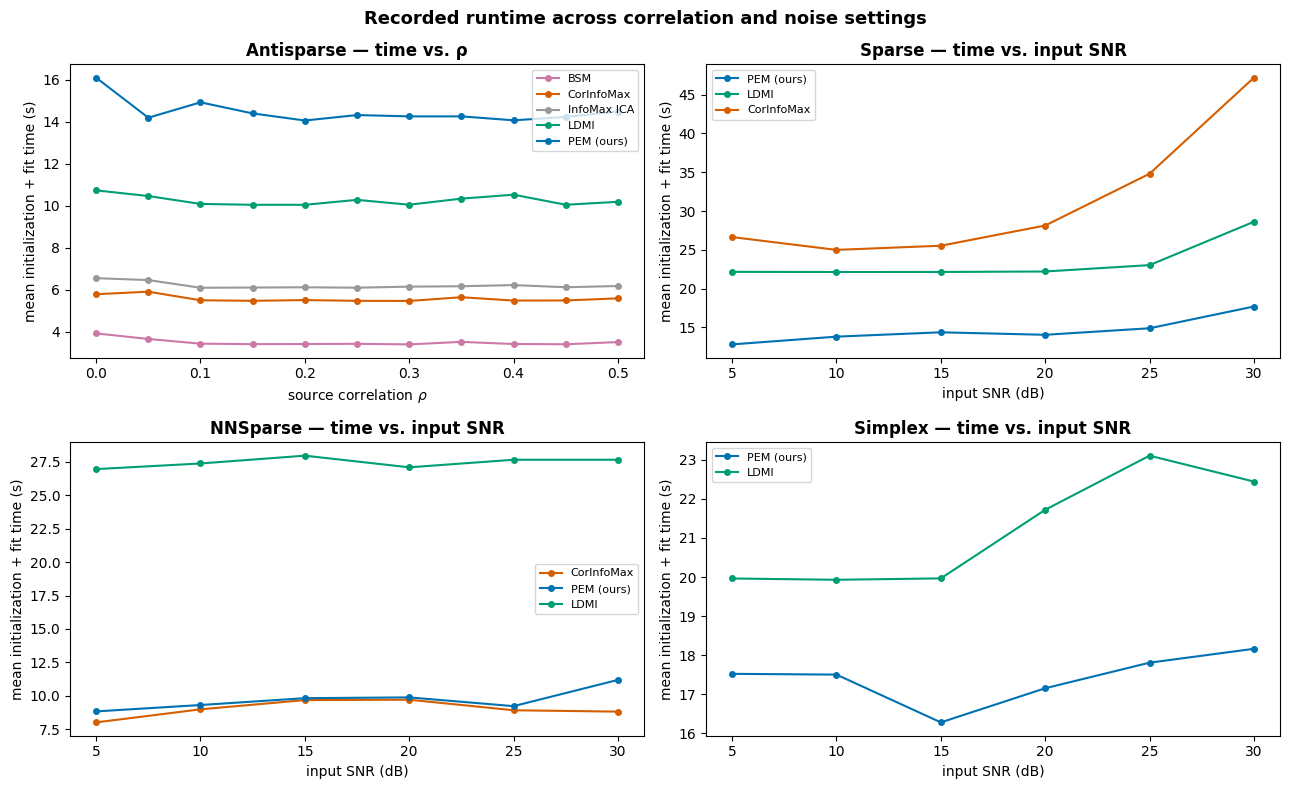

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (exp, df) in zip(axes.ravel(), data.items()):
    sec = SECONDARY[exp]
    for a in summaries[exp].index:
        sub = df[df.Algorithm == a]
        key = sub[sec] if sec == "rho" else sub[sec].round(0)
        s = sub.groupby(key)["execution_time"].mean()
        ax.plot(s.index, s.values, marker="o", ms=4, color=COLOR[a], label=a)
    ax.set_xlabel("source correlation $\\rho$" if sec == "rho" else "input SNR (dB)")
    ax.set_ylabel("mean initialization + fit time (s)")
    ax.set_title(f"{exp} — time vs. {'ρ' if sec=='rho' else 'input SNR'}", fontweight="bold")
    ax.legend(fontsize=8)
fig.suptitle("Recorded runtime across correlation and noise settings", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

## 5. Practical CPU execution at the experiment settings


In [6]:
pem_medians = []
print("PEM recorded initialization + fit times (seconds)")
for exp, df in data.items():
    times = df.loc[df.Algorithm.eq("PEM (ours)"), "execution_time"]
    pem_medians.append(times.median())
    print(f"{exp:11s}: median {times.median():.2f}; "
          f"mean ± sample SD {times.mean():.2f} ± {times.std(ddof=1):.2f}; "
          f"{len(times)} recorded runs")
print(f"\nPEM medians range from {min(pem_medians):.2f} to {max(pem_medians):.2f} s "
      "for these five-source experiments.")
print("These configuration-specific recorded times illustrate practical CPU execution; "
      "they do not establish controlled speed differences between algorithms.")


PEM recorded initialization + fit times (seconds)
Antisparse : median 14.13; mean ± sample SD 14.48 ± 1.41; 330 recorded runs
Sparse     : median 14.06; mean ± sample SD 14.60 ± 2.41; 180 recorded runs
NNSparse   : median 9.25; mean ± sample SD 9.71 ± 1.58; 180 recorded runs
Simplex    : median 16.45; mean ± sample SD 17.40 ± 1.98; 180 recorded runs

PEM medians range from 9.25 to 16.45 s for these five-source experiments.
These configuration-specific recorded times illustrate practical CPU execution; they do not establish controlled speed differences between algorithms.


### Interpretation and provenance limitations

- The practical observation is that these small source-separation experiments run in seconds to tens of seconds on the recorded CPU implementations. No relative-speed conclusion is needed.
- Methods differ in supplied sample counts, inference horizons, stopping criteria, initialization, and diagnostics. In particular, LDMI/CorInfoMax (Batch) uses 10,000 samples over 5,000 iterations, while the online methods process 100,000 samples once. InfoMax ICA uses a separate batch ICA implementation on 100,000 samples.
- Timed intervals include internal ground-truth diagnostics even when plotting is disabled, and may include first-use JIT compilation. Diagnostic schedules also differ: for example, the antisparse online CorInfoMax run has no ground-truth diagnostic input, while PEM does. We do not attribute observed runtime differences to a particular computational mechanism.
- The result files do not establish CPU model, thread count, exact original package versions, or a common host. Software versions in the export metadata describe **this aggregation**, not the environment that produced the original timings.
- The reported mean and sample standard deviation pool condition sweeps; they are not confidence intervals or estimates from 330/180 independent seeds. Missing method/domain combinations were not run.


## 6. Publication table and provenance export

Merge all five methods and four domains into one **mean ± sample SD** table (seconds). Missing combinations are shown as an em dash. The CSV retains unrounded summary statistics, run counts, and actual fit input budgets; it includes all 20 method/domain combinations with zero runs and blank statistics for missing combinations. The JSON records checksums of the four result files and matching implementation/driver files, condition grids, sample and iteration budgets, and the software used only to summarize the existing timings. Running this cell performs no fitting or benchmarking and does not overwrite standalone plot assets.


In [7]:
from pathlib import Path
import hashlib
import importlib
import json
import platform
import sys

_runtime_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "Simulations/AnalyzeSimulationResults/Computation_Time_Comparison.ipynb").is_file()
     and (p / "src/python_utils/python_utils.py").is_file()), None)
if _runtime_root is None:
    raise RuntimeError("Run the notebook from within the repository.")
_runtime_results = _runtime_root / "Simulations/Results"
_runtime_methods = [
    ("PEM (ours)", "PEM"),
    ("CorInfoMax", "CorInfoMax (Online)"),
    ("LDMI", "CorInfoMax (Batch)"),
    ("BSM", "BSM"),
    ("InfoMax ICA", "InfoMax ICA"),
]
_runtime_table = pd.DataFrame(index=[pub for _, pub in _runtime_methods],
                              columns=list(FILES), dtype=object)
_runtime_rows = []
for _runtime_exp, _runtime_df in data.items():
    for _runtime_internal, _runtime_publication in _runtime_methods:
        _runtime_sub = _runtime_df.loc[_runtime_df.Algorithm.eq(_runtime_internal)]
        _runtime_times = _runtime_sub["execution_time"]
        _runtime_present = len(_runtime_sub) > 0
        _runtime_row = {
            "domain": _runtime_exp, "method": _runtime_publication,
            "runs": len(_runtime_sub),
            "fit_input_samples": (int(_runtime_sub["fit_input_samples"].iloc[0])
                                  if _runtime_present else np.nan),
            "mean_s": _runtime_times.mean(), "std_s": _runtime_times.std(ddof=1),
            "median_s": _runtime_times.median(),
            "min_s": _runtime_times.min(), "max_s": _runtime_times.max(),
        }
        _runtime_rows.append(_runtime_row)
        _runtime_table.loc[_runtime_publication, _runtime_exp] = (
            f"{_runtime_row['mean_s']:.2f} ± {_runtime_row['std_s']:.2f}"
            if _runtime_present else "—")
_runtime_summary = pd.DataFrame(_runtime_rows)
_runtime_summary["fit_input_samples"] = _runtime_summary["fit_input_samples"].astype("Int64")
_runtime_csv = _runtime_results / "bss_wall_clock_runtime_summary.csv"
_runtime_summary.to_csv(_runtime_csv, index=False, float_format="%.17g")

_runtime_driver_names = {
    "Antisparse": "PredictiveBSS_Correlated_Antisparse_10by5.py",
    "Sparse": "PredictiveBSS_Noisy_Sparse_10by5.py",
    "NNSparse": "PredictiveBSS_Noisy_NNSparse_10by5.py",
    "Simplex": "PredictiveBSS_Noisy_Simplex_10by5.py",
}
_runtime_sources = [
    "src/python_utils/python_utils.py", "src/bss/PredictiveDecorrBSS.py",
    "src/bss/CorInfoMaxBSS.py", "src/bss/LDMIBSS.py", "src/bss/BSMBSS.py",
    "src/bss/ica_utils.py", "src/bss/BSSbase.py",
    "src/other_methods/src/CorInfoMaxBSS.py",
    *[f"Simulations/PredictiveBSS/{name}" for name in _runtime_driver_names.values()],
]
_runtime_files_meta = {}
for _runtime_exp, _runtime_filename in FILES.items():
    _runtime_path = _runtime_results / _runtime_filename
    _runtime_df = data[_runtime_exp]
    _runtime_condition = SECONDARY[_runtime_exp]
    _runtime_conditions = sorted(float(v) for v in _runtime_df[_runtime_condition].unique())
    _runtime_per_condition = []
    for (_runtime_model, _runtime_value), _runtime_group in _runtime_df.groupby(
            ["Model", _runtime_condition], sort=True):
        _runtime_per_condition.append({"recorded_model": _runtime_model,
                                       "condition_value": float(_runtime_value),
                                       "runs": len(_runtime_group)})
    _runtime_files_meta[_runtime_exp] = {
        "path": str(_runtime_path.relative_to(_runtime_root)),
        "sha256": hashlib.sha256(_runtime_path.read_bytes()).hexdigest(),
        "driver": f"Simulations/PredictiveBSS/{_runtime_driver_names[_runtime_exp]}",
        "recorded_columns": [name for name in _runtime_df.columns
                             if name not in ["Algorithm", "fit_input_samples"]],
        "recorded_model_names": sorted(_runtime_df["Model"].unique().tolist()),
        "total_records": len(_runtime_df),
        "seed_values": sorted(int(v) for v in _runtime_df["seed"].unique()),
        "sweep": {"column": _runtime_condition, "values": _runtime_conditions},
        "input_snr_values_db": sorted(float(v) for v in _runtime_df["SNRinp"].unique()),
        "counts_per_model_and_condition": _runtime_per_condition,
    }
_runtime_metadata = {
    "description": "Aggregation of existing initialization-and-fitting CPU wall-clock times; no benchmark rerun",
    "analysis_notebook": "Simulations/AnalyzeSimulationResults/Computation_Time_Comparison.ipynb",
    "statistic": {"units": "seconds", "mean": "arithmetic mean of recorded execution_time",
                  "standard_deviation": "sample standard deviation, ddof=1; not a confidence interval",
                  "pooling": "conditions pooled within method/domain; 30 seeds repeated across 11 or 6 conditions",
                  "missing_combinations": "CSV has runs=0, blank statistics and blank input budget"},
    "problem_dimensions": {"n_sources": 5, "n_mixtures": 10},
    "method_budgets_from_drivers": {
        "PEM": {"input_samples": 100000, "streaming_passes": 1,
                "max_inner_iterations": {"Antisparse": 250, "Sparse": 100,
                                          "NNSparse": 100, "Simplex": 100}},
        "CorInfoMax (Online)": {"input_samples": 100000, "streaming_passes": 1,
                               "max_inner_iterations": {"Antisparse": 250, "Sparse": 500,
                                                         "NNSparse": 250},
                               "implementation_note": "Sparse uses src/other_methods/src/CorInfoMaxBSS.py; other domains use src/bss/CorInfoMaxBSS.py"},
        "CorInfoMax (Batch)": {"input_samples": 10000, "batch_iterations": 5000,
                              "recorded_model": "LDMIBSS"},
        "BSM": {"input_samples": 100000, "streaming_passes": 1,
                "max_inner_iterations": {"Antisparse": 10}},
        "InfoMax ICA": {"input_samples": 100000, "optimization": "MNE batch extended InfoMax",
                        "configured_max_iter": 10000},
    },
    "timing_scope": {
        "timer": "time.perf_counter around initialization and fitting",
        "included": ["construction and initialization", "fit", "internal diagnostics",
                     "first-use Numba JIT compilation when triggered",
                     "InfoMax ICA: MNE setup and source extraction"],
        "excluded": ["data generation", "external post-fit metrics", "result serialization"],
        "caveats": ["hyperparameters, input budgets, inference horizons, and stopping criteria differ",
                    "ground-truth diagnostics run with plotting disabled and schedules differ by method",
                    "PEM stores a covariance-history copy per sample in the inspected implementation",
                    "current source hashes document inspected implementations, not proven historical producer revisions"],
    },
    "producer_environment": {"cpu_model": None, "thread_configuration": None,
                             "software_versions": None, "common_host_verified": False,
                             "note": "These fields are not recorded in the input result files."},
    "aggregation_environment": {"python": sys.version, "platform": platform.platform(),
                                "software_versions": {name: importlib.import_module(name).__version__
                                                      for name in ["numpy", "pandas", "matplotlib", "IPython"]}},
    "input_result_files": _runtime_files_meta,
    "inspected_source_sha256": {
        name: hashlib.sha256((_runtime_root / name).read_bytes()).hexdigest()
        for name in _runtime_sources if (_runtime_root / name).is_file()},
    "summary_csv_sha256": hashlib.sha256(_runtime_csv.read_bytes()).hexdigest(),
}
_runtime_metadata_path = _runtime_results / "bss_wall_clock_runtime_metadata.json"
_runtime_metadata_path.write_text(json.dumps(_runtime_metadata, indent=2, sort_keys=True) + "\n")
print("Recorded initialization + fit time, mean ± sample SD (seconds)")
print(_runtime_table.to_string())
print("\nSaved:", _runtime_csv.relative_to(_runtime_root))
print("Saved:", _runtime_metadata_path.relative_to(_runtime_root))


Recorded initialization + fit time, mean ± sample SD (seconds)
                       Antisparse        Sparse      NNSparse       Simplex
PEM                  14.48 ± 1.41  14.60 ± 2.41   9.71 ± 1.58  17.40 ± 1.98
CorInfoMax (Online)   5.58 ± 0.42  31.21 ± 8.49   9.02 ± 0.86             —
CorInfoMax (Batch)   10.26 ± 0.88  23.38 ± 3.02  27.45 ± 2.32  21.19 ± 2.04
BSM                   3.51 ± 0.62             —             —             —
InfoMax ICA           6.21 ± 0.30             —             —             —

Saved: Simulations/Results/bss_wall_clock_runtime_summary.csv
Saved: Simulations/Results/bss_wall_clock_runtime_metadata.json
